In [1]:
try:
     from dlroms import*
except:
     !pip install --no-deps git+https://github.com/NicolaRFranco/dlroms.git
     from dlroms import*
import numpy as np
import matplotlib.pyplot as plt
clc()

## Ex 1 - **Hailstone shield design** (Linear elasticity)

### FOM solver code

In [ ]:
mesh = fe.unitsquaremesh(40, 40) # rescaling from [0cm,6cm]x[0cm,6cm] to [0,1]x[0,1]
Vh = fe.space(mesh, 'CG', 1, vector_valued = True)
Dh = fe.space(mesh, 'DG', 0)
clc()

def FOMsolver(mu):
  r, m, theta = mu
  x0, delta = 0.5, 0.1 # hailstone of diameter 1.2cm becomes of radius 0.1 in the rescaled metric

  from ufl_legacy import nabla_div
  from scipy.sparse.linalg import spsolve
  from scipy.sparse import csr_matrix
  from fenics import Constant, DirichletBC, nabla_grad, Identity, TrialFunction, TestFunction, dot, dx, ds, inner, assemble

  # Boundary conditions
  tol = 1e-5
  def clamped_boundary(x, on_boundary):
      return on_boundary and x[1]<tol
  bc = DirichletBC(Vh, Constant((0, 0)), clamped_boundary)

  # Auxiliary definitions
  lambda_ = fe.interpolate(lambda x: r*(x[1]>0.5)*1.0+1.0*(x[1]<=0.5), Dh)
  nu = fe.interpolate(lambda x: (x[1]>0.5)*r+1.0*(x[1]<=0.5), Dh)

  def epsilon(u):
      return 0.5*(nabla_grad(u) + nabla_grad(u).T)

  def sigma(u):
      return lambda_*nabla_div(u)*Identity(2) + 2*nu*epsilon(u)

  # Variational problem
  u = TrialFunction(Vh)
  v = TestFunction(Vh)
  f = Constant((0, -1))
  T = fe.interpolate(lambda x: [m*np.cos(theta-np.pi/2)*(x[1] > 0.99)*(np.abs(x[0]-x0)<(delta+tol)),
                                   m*np.sin(theta-np.pi/2)*(x[1] > 0.99)*(np.abs(x[0]-x0)<(delta+tol))], Vh)

  a = inner(sigma(u), epsilon(v))*dx
  L = dot(f, v)*dx + dot(T, v)*ds

  # Assembling and adjusting
  A = assemble(a)
  F = assemble(L)
  bc.apply(A)
  bc.apply(F)

  A = csr_matrix(A.array())
  F = F[:]

  # Solving
  u = spsolve(A, F)
  clc()
  return u

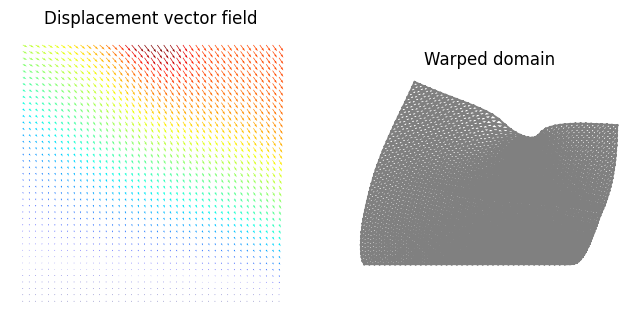

In [ ]:
u = FOMsolver([0.75, 1, 0.4])

plt.figure(figsize = (8, 4))
plt.subplot(1, 2, 1)
fe.plot(u, Vh)
plt.title("Displacement vector field")
plt.subplot(1, 2, 2)
fe.plot(u, Vh, warp = True)
plt.title("Warped domain")
None

## Ex 2 - **Chemical mixer** (Advection-diffusion)

### FOM solver code

In [ ]:
# Problem setup
domain = fe.rectangle((0, 0), (3, 2))-fe.circle((0.95, 0.7), 0.25)-fe.circle((1.5, 1.35), 0.25)-fe.circle((2.05, 0.7), 0.25)
mesh = fe.mesh(domain, stepsize = 0.05)

left = lambda x: x[0]<1e-6
right = lambda x: 3-x[0]<1e-12
circle = lambda x0, r: (lambda x: ((x[0]-x0[0])**2 + (x[1]-x0[1])**2)**0.5 < r+1e-3)

def inflows(b0, b1, b2, b3):
  return [[left,                       lambda x: [b0*np.exp(-25*(x[1]-1)**2), 0.0]],
          [circle((0.95, 0.70), 0.25), lambda x: [b1*(-x[1]+0.70),    b1*(x[0]-0.95)]],
          [circle((1.50, 1.35), 0.25), lambda x: [b2*(-x[1]+1.35),    b2*(x[0]-1.50)]],
          [circle((2.05, 0.70), 0.25), lambda x: [b3*(-x[1]+0.70),    b3*(x[0]-2.05)]]]

outflows = [right]

In [ ]:
# Auxiliary solver for the Stokes' problem
def stokes_solver(mesh, inflows, outflows, source = [0.0, 0.0]):
  from fenics import FiniteElement, NodalEnrichedElement, FunctionSpace, VectorElement, TrialFunctions, TestFunctions
  from fenics import inner, grad, dx, div, assemble, DirichletBC, Constant, Expression
  from scipy.sparse.linalg import spsolve
  from scipy.sparse import csr_matrix

  pP1  = FiniteElement("CG", mesh.ufl_cell(), 1)
  vP1B = VectorElement(NodalEnrichedElement(FiniteElement("CG",       mesh.ufl_cell(), 1),
                                            FiniteElement("Bubble",   mesh.ufl_cell(), mesh.topology().dim() + 1)))

  pspace, vspace = pP1, vP1B
  W = FunctionSpace(mesh, vspace * pspace)
  W0 = FunctionSpace(mesh, vspace)
  (b, p) = TrialFunctions(W)
  (v, q) = TestFunctions(W)

  space = fe.space(mesh, "CG", 1, vector_valued = True, bubble = True)
  f = fe.interpolate(source, space)

  a = inner(grad(b), grad(v))*dx - div(v)*p*dx - q*div(b)*dx
  L = inner(f, v)*dx

  def outflow(x):
    result = False
    for out in outflows:
      result = result or out(x)
    return result

  def inflow(x):
    result = False
    for infl in inflows:
      result = result or infl[0](x)
    return result

  def walls(x):
    return not(outflow(x) or inflow(x))

  noslip = DirichletBC(W.sub(0), Constant((0.0, 0.0)), lambda x, on: on and walls(x))
  def make_bc(i):
    return DirichletBC(W.sub(0), fe.interpolate(inflows[i][1], W0), lambda x, on: on and inflows[i][0](x))
  ins = [make_bc(i) for i in range(len(inflows))]

  A = assemble(a)
  F = assemble(L)

  for bc in [noslip, *ins]:
    bc.apply(A)
    bc.apply(F)

  A = csr_matrix(A.array())
  F = F[:]

  bp = spsolve(A, F)
  bp_f = fe.asfunction(bp, W)

  from fenics import dof_to_vertex_map
  Vh = fe.space(mesh,'CG', 1)
  Vb = fe.space(mesh,'CG', 1, vector_valued = True)
  nvertices = mesh.coordinates().shape[0]
  b = bp_f.compute_vertex_values(mesh)[:2*nvertices].reshape(2, -1).T
  indexes = dof_to_vertex_map(Vh)
  b = b[indexes].reshape(-1)
  return b

In [ ]:
# Stokes pre-computation
def bi(i):
  e = np.zeros(4)
  e[i] = 1
  return stokes_solver(mesh, inflows(*e), outflows)

b0, b1, b2, b3 = [bi(i) for i in range(4)]

Calling FFC just-in-time (JIT) compiler, this may take some time.


Level 25:FFC:Calling FFC just-in-time (JIT) compiler, this may take some time.
INFO:FFC:Compiling element ffc_element_afa50c16163fd6db5cadce9c8cb245fc6081510f

INFO:FFC:Compiler stage 1: Analyzing element(s)
INFO:FFC:--------------------------------------
INFO:FFC:  
INFO:FFC:Compiler stage 1 finished in 0.00311732 seconds.

INFO:FFC:Compiler stage 2: Computing intermediate representation
INFO:FFC:-------------------------------------------------------
INFO:FFC:  Computing representation of 1 elements
DEBUG:FFC:  Reusing element from cache
DEBUG:FFC:  Reusing element from cache
DEBUG:FFC:  Reusing element from cache
DEBUG:FFC:  Reusing element from cache
DEBUG:FFC:  Reusing element from cache
INFO:FFC:  Computing representation of 1 dofmaps
DEBUG:FFC:  Reusing element from cache
INFO:FFC:  Computing representation of 0 coordinate mappings
INFO:FFC:  Computing representation of integrals
INFO:FFC:  Computing representation of forms
INFO:FFC:  
INFO:FFC:Compiler stage 2 finished in 0.381

Calling FFC just-in-time (JIT) compiler, this may take some time.


Level 25:FFC:Calling FFC just-in-time (JIT) compiler, this may take some time.
INFO:FFC:Compiling element ffc_element_00f5c99235d7c07341f6c63ebd682228a61240ae

INFO:FFC:Compiler stage 1: Analyzing element(s)
INFO:FFC:--------------------------------------
INFO:FFC:  
INFO:FFC:Compiler stage 1 finished in 0.00980163 seconds.

INFO:FFC:Compiler stage 2: Computing intermediate representation
INFO:FFC:-------------------------------------------------------
INFO:FFC:  Computing representation of 1 elements
DEBUG:FFC:  Reusing element from cache
DEBUG:FFC:  Reusing element from cache
DEBUG:FFC:  Reusing element from cache
INFO:FFC:  Computing representation of 1 dofmaps
DEBUG:FFC:  Reusing element from cache
INFO:FFC:  Computing representation of 0 coordinate mappings
INFO:FFC:  Computing representation of integrals
INFO:FFC:  Computing representation of forms
INFO:FFC:  
INFO:FFC:Compiler stage 2 finished in 0.0315878 seconds.

INFO:FFC:Compiler stage 3: Optimizing intermediate representati

Calling FFC just-in-time (JIT) compiler, this may take some time.


...

Level 25:FFC:Calling FFC just-in-time (JIT) compiler, this may take some time.
INFO:FFC:Compiling element ffc_element_d5643f067132f3d65a9634649b4968a1f06bd331

INFO:FFC:Compiler stage 1: Analyzing element(s)
INFO:FFC:--------------------------------------
INFO:FFC:  
INFO:FFC:Compiler stage 1 finished in 0.00392699 seconds.

INFO:FFC:Compiler stage 2: Computing intermediate representation
INFO:FFC:-------------------------------------------------------
INFO:FFC:  Computing representation of 1 elements
DEBUG:FFC:  Reusing element from cache
DEBUG:FFC:  Reusing element from cache
DEBUG:FFC:  Reusing element from cache
INFO:FFC:  Computing representation of 1 dofmaps
DEBUG:FFC:  Reusing element from cache
INFO:FFC:  Computing representation of 0 coordinate mappings
INFO:FFC:  Computing representation of integrals
INFO:FFC:  Computing representation of forms
INFO:FFC:  
INFO:FFC:Compiler stage 2 finished in 0.0137079 seconds.

INFO:FFC:Compiler stage 3: Optimizing intermediate representati

Calling FFC just-in-time (JIT) compiler, this may take some time.


Level 25:FFC:Calling FFC just-in-time (JIT) compiler, this may take some time.
INFO:FFC:Compiling element ffc_element_743bff938da0ea6c63565a09a1ac19cba7bc6394

INFO:FFC:Compiler stage 1: Analyzing element(s)
INFO:FFC:--------------------------------------
INFO:FFC:  
INFO:FFC:Compiler stage 1 finished in 0.00195312 seconds.

INFO:FFC:Compiler stage 2: Computing intermediate representation
INFO:FFC:-------------------------------------------------------
INFO:FFC:  Computing representation of 1 elements
DEBUG:FFC:  Reusing element from cache
DEBUG:FFC:  Reusing element from cache
DEBUG:FFC:  Reusing element from cache
INFO:FFC:  Computing representation of 1 dofmaps
DEBUG:FFC:  Reusing element from cache
INFO:FFC:  Computing representation of 0 coordinate mappings
INFO:FFC:  Computing representation of integrals
INFO:FFC:  Computing representation of forms
INFO:FFC:  
INFO:FFC:Compiler stage 2 finished in 0.0146947 seconds.

INFO:FFC:Compiler stage 3: Optimizing intermediate representati

Calling FFC just-in-time (JIT) compiler, this may take some time.


Level 25:FFC:Calling FFC just-in-time (JIT) compiler, this may take some time.
INFO:FFC:Compiling form ffc_form_29ec5df0fa6debb0d37a27714a605cd6d281ee77

INFO:FFC:Compiler stage 1: Analyzing form(s)
INFO:FFC:-----------------------------------
DEBUG:FFC:  Preprocessing form using 'uflacs' representation family.
INFO:FFC:  
INFO:FFC:  Geometric dimension:       2
  Number of cell subdomains: 0
  Rank:                      1
  Arguments:                 '(v_0)'
  Number of coefficients:    1
  Coefficients:              '[f_100]'
  Unique elements:           'Mixed<Vector<2 x NodalEnriched(CG1(?,?), B3(?,?))>, CG
                             1(?,?)>, Vector<2 x NodalEnriched(CG1(?,?), B3(?,?))>, 
                             Vector<2 x CG1(?,?)>'
  Unique sub elements:       'Mixed<Vector<2 x NodalEnriched(CG1(?,?), B3(?,?))>, CG
                             1(?,?)>, Vector<2 x NodalEnriched(CG1(?,?), B3(?,?))>, 
                             Vector<2 x CG1(?,?)>, CG1(?,?), NodalEnriched(

In [ ]:
# FOM solver definition
Vh = fe.space(mesh, 'CG', 1)
Vb = fe.space(mesh, 'CG', 1, vector_valued = True)
clc()

def FOMsolver(mu):
  c1, c2, c3 = mu
  from fenics import grad, inner, dx, solve, TrialFunction, TestFunction, Function, Constant, DirichletBC, assemble
  from scipy.sparse.linalg import spsolve
  b = fe.asfunction(b0 + c1*b1 + c2*b2 + c3*b3, Vb)

  def a(u, v):
    return 0.005*inner(grad(u), grad(v))*dx + inner(b, grad(u))*v*dx

  A = fe.assemble(a, Vh)
  F = np.zeros(Vh.dim())
  bc = fe.DirichletBC(left, lambda x: np.exp(-25*(x[1]-1)**2))
  A = fe.applyBCs(A, Vh, bc)
  F = fe.applyBCs(F, Vh, bc)
  u = spsolve(A, F)
  clc()
  return u

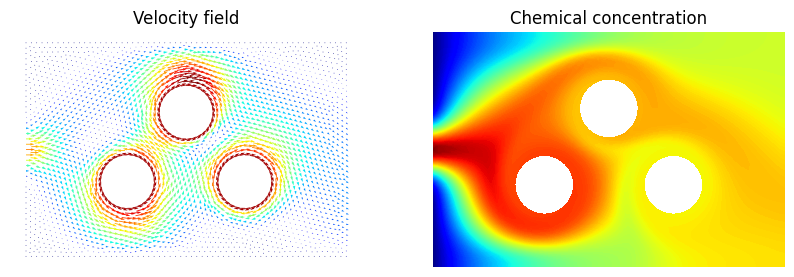

In [ ]:
u = FOMsolver([5, -5, -5])

plt.figure(figsize = (10, 6))
plt.subplot(1, 2, 1)
fe.plot(b0 + 5*b1 -5*b2 -5*b3, Vb)
plt.title("Velocity field")
plt.subplot(1, 2, 2)
fe.plot(u, Vh)
plt.title("Chemical concentration")
None

## Ex 3 - **Catching electrons in a bi-crystal** (Schrödinger's equation)

### FOM solver code

In [2]:
## Construction of the geometry
domain = fe.circle((0, 0), 1.0/np.pi)
mesh = fe.mesh(domain, stepsize = 0.02)
Vh = fe.space(mesh, 'CG', 1)
nh = Vh.dim()
clc()

## Definition of the Full Order Model (FOM)
def FOMsolver(E, deltaV0, steps = 99, dt = 1e-3):
  from fenics import inner, grad, dx, div, assemble, DirichletBC, Constant, Expression
  from scipy.sparse.linalg import spsolve
  from scipy.sparse import bmat

  potential = fe.interpolate(lambda x: E*(x[0]/np.sqrt(2.0) - x[1]/np.sqrt(2.0)) + deltaV0*(x[1] > 0), Vh)

  S = fe.assemble(lambda u, v: inner(grad(u), grad(v))*dx, Vh)
  M = fe.assemble(lambda u, v: u*v*dx, Vh)
  V = fe.assemble(lambda u, v: potential*u*v*dx, Vh)

  bc = fe.DirichletBC(lambda x: True, 0.0)
  B = S + V
  B = fe.applyBCs(B, Vh, bc)
  M = fe.applyBCs(M, Vh, bc)

  A = bmat([[M, -dt*B], [dt*B, M]])
  M2 = bmat([[M, 0*M], [0*M, M]])

  u0_real = fe.interpolate(lambda x: np.exp(-100*(x[0]**2+x[1]**2)), Vh)
  u0_imag = fe.interpolate(0.0, Vh)

  u0_real_vec = fe.dofs(u0_real)
  u0_imag_vec = fe.dofs(u0_imag)
  states = [np.concatenate((u0_real_vec, u0_imag_vec))]

  for n in range(steps):
    now = states[-1]
    rhs = M2 @ now
    rhs[:nh] = fe.applyBCs(rhs[:nh], Vh, bc)
    rhs[nh:] = fe.applyBCs(rhs[nh:], Vh, bc)
    next = spsolve(A, rhs)
    states.append(next)

  clc()

  return np.stack(states)


## Auxiliary functions for Task (iii)
from fenics import dx
M = fe.assemble(lambda u, v: u*v*dx, Vh)
clc()

def probabilities(u):
  unnormalized_probabilities = (u.reshape(-1, 2, nh)**2).sum(axis = 1)
  integrals = (unnormalized_probabilities @ M).sum(axis = -1)
  return unnormalized_probabilities/integrals.reshape(-1, 1)

def caught(prob):
  T = 0.1
  times = np.linspace(0, T, 100)
  indicator = fe.dofs(fe.interpolate(lambda x: x[1]>0, Vh))
  return (prob @ M @ indicator).mean()

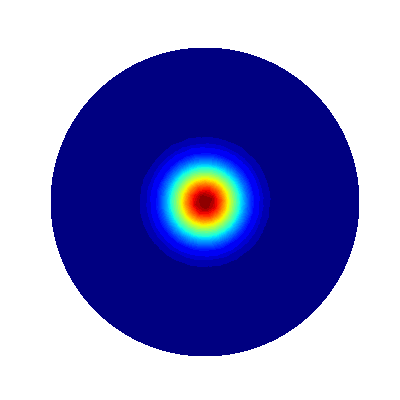

In [3]:
u = FOMsolver(800, 50)
fe.animate(probabilities(u), Vh)